# 02 First look
What does a user's life on this service look like? Look at raw rows before any aggregate.

**Before running anything:** write your story of how each table was produced, and what you expect one user's timeline to look like.

**My data-generating story (before):** 


In [1]:
import glob
import pandas as pd
import matplotlib.pyplot as plt

ROOT = "../data/ContentWiseImpressions/data/ContentWiseImpressions/CW10M"
inter = pd.read_parquet(f"{ROOT}/interactions").reset_index()
inter['t'] = pd.to_datetime(inter.utc_ts_milliseconds, unit='ms')
cols = ['t', 'series_id', 'item_id', 'episode_number', 'item_type', 'interaction_type', 'vision_factor', 'recommendation_id']
counts = inter.user_id.value_counts()

### 2.1 How active are users?
**Question:** How are interactions spread across users?

**Prediction:** _write before running_

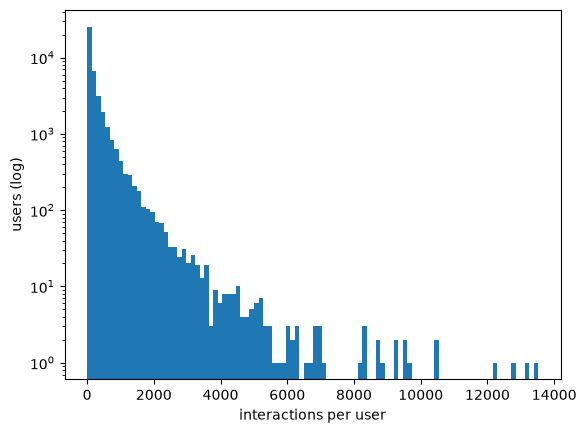

In [7]:
counts.plot.hist(bins=100, logy=True, xlabel='interactions per user', ylabel='users (log)')
plt.show()

**Observation:** 

**Decision:** 

### 2.2 A random user
**Question:** What does an ordinary user's timeline look like, row by row?

**Prediction:** Just some videos on the watch I guess, continuing same series for long. Changing show midway, continuing it back...

In [3]:
u = counts.sample(1, random_state=0).index[0]
inter.loc[inter.user_id == u, cols].sort_values('t').head(60)

,t,series_id,item_id,episode_number,item_type,interaction_type,vision_factor,recommendation_id
26648,2019-01-07 17:07:47,24096,12492,2,3,0,0.28,-1
111972,2019-01-08 13:51:34,24096,12492,2,3,0,1.00,-1
111988,2019-01-08 15:36:31,24096,84230,3,3,0,0.89,-1
231400,2019-01-09 15:03:21,24096,12492,2,3,0,0.10,99096
230829,2019-01-09 17:06:17,12436,87402,3,3,0,0.83,162881
420083,2019-01-11 17:05:33,7569,71987,2,3,0,0.15,118496
720885,2019-01-14 13:15:20,25454,120430,18,3,0,0.90,-1
742785,2019-01-14 16:26:28,7569,71987,2,3,0,0.62,-1
929482,2019-01-16 14:45:44,7569,71987,2,3,0,0.98,77854
938241,2019-01-16 15:57:11,7569,68542,3,3,0,0.88,-1


**Observation:** Yep, normal pattern. nice.

**Decision:** Nothinig atp

### 2.3 The heaviest user
**Question:** Is the heaviest user a person, a household, or something else?

**Prediction:** Unless the household is able to access the platform on multiple devices, we can assume only one person using the platform at a time. In either case, breaks are something that would occasionally hinder an individual from heavy usage. a collective house should do it well.

In [4]:
u = counts.index[0]
inter.loc[inter.user_id == u, cols].sort_values('t').head(60)

,t,series_id,item_id,episode_number,item_type,interaction_type,vision_factor,recommendation_id
8880,2019-01-07 09:04:53,2209,33282,24,3,0,1.0,-1
8881,2019-01-07 09:23:37,2209,109768,25,3,0,1.0,-1
8882,2019-01-07 09:33:02,2209,140352,26,3,0,1.0,-1
8883,2019-01-07 09:40:59,2209,123979,27,3,0,1.0,-1
8884,2019-01-07 10:14:42,2209,22623,28,3,0,1.0,-1
8885,2019-01-07 10:14:53,2209,23113,29,3,1,-1.0,-1
8886,2019-01-07 10:18:13,2209,23113,29,3,0,1.0,-1
8887,2019-01-07 10:18:21,2209,23113,29,3,1,-1.0,-1
8890,2019-01-07 10:20:58,13512,15403,9,3,1,-1.0,-1
8891,2019-01-07 10:21:13,11895,122274,28,3,1,-1.0,-1


**Observation:** 

**Decision:** 

### 2.4 One timeline as a picture
**Question:** Does the user binge one series, hop between many, or come back in bursts?

**Prediction:** _write before running_

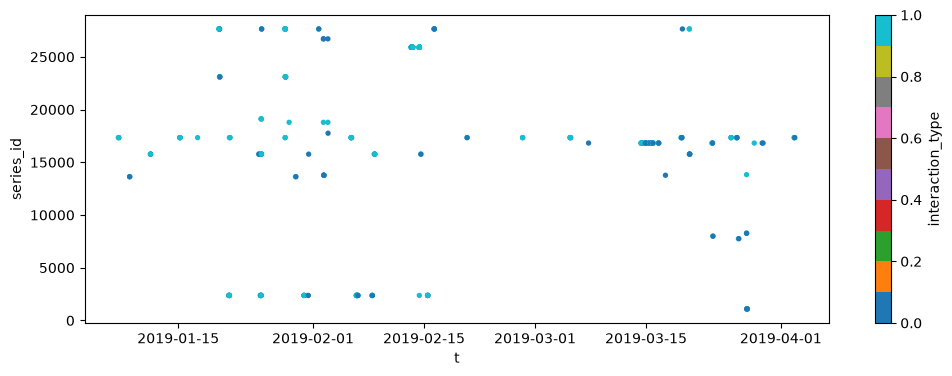

In [5]:
u = counts.sample(1, random_state=1).index[0]
d = inter[inter.user_id == u]
d.plot.scatter(x='t', y='series_id', c='interaction_type', cmap='tab10', s=8, figsize=(12, 4))
plt.show()

**Observation:** 

**Decision:** 

## Decision for this notebook
_Rewrite the data-generating story from what you saw. What surprised you, and which later decision does each surprise affect?_